# BEAM RL task: simulation and parameter recovery

Task: two 2-armed bandits (75% / 25% arms), **50 trials per bandit, randomly interleaved, 100 trials total**.
Model: Rescorla-Wagner Q-learning with a softmax choice rule (learning rate α, inverse temperature β).

The simulation and fitting functions are in `beam_rl.py`. This notebook:

1. Simulates the ten paired (α, β) groups from `Interleaved_75_25.ipynb` and plots learning, with 10 and with 100 agents per group.
2. Runs parameter recovery on those paired groups.
3. Runs parameter recovery on a crossed α × β grid, so the two parameters vary independently.
4. Compares recovery for the 100-trial task against a 200-trial task.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

import beam_rl as rl

SEED = 10
os.makedirs("outputs", exist_ok=True)

alpha_parameters = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]
beta_parameters = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5]

## 1. Learning in the ten paired groups

Group *i* uses `alpha_parameters[i]` with `beta_parameters[i]`, as in the original notebook.
Curves are plotted against the **within-bandit trial (1–50)**, i.e. the number of times that bandit has been shown,
since a bandit's Q-values only change on its own trials.

In [2]:
def simulate_paired_groups(agents_per_group, seed):
    rng = np.random.default_rng(seed)
    alphas = np.repeat(alpha_parameters, agents_per_group)
    betas = np.repeat(beta_parameters, agents_per_group)
    data = rl.simulate_group(alphas, betas, rng)
    data["group"] = (data["agent"] - 1) // agents_per_group
    return data

sim_10 = simulate_paired_groups(10, SEED)
sim_100 = simulate_paired_groups(100, SEED)

# every agent should have 100 trials, 50 per bandit
for name, data in [("10 per group", sim_10), ("100 per group", sim_100)]:
    counts = data.groupby(["agent", "pair"]).size().unstack()
    assert (counts == rl.TRIALS_PER_PAIR).all().all()
    print(f"{name}: {data['agent'].nunique()} agents, {len(data)} observations, "
          f"{rl.TRIALS_PER_PAIR} trials per bandit for every agent")

sim_100.round(3).to_csv("outputs/simulated_trials_100_per_group.csv", index=False)

10 per group: 100 agents, 10000 observations, 50 trials per bandit for every agent
100 per group: 1000 agents, 100000 observations, 50 trials per bandit for every agent


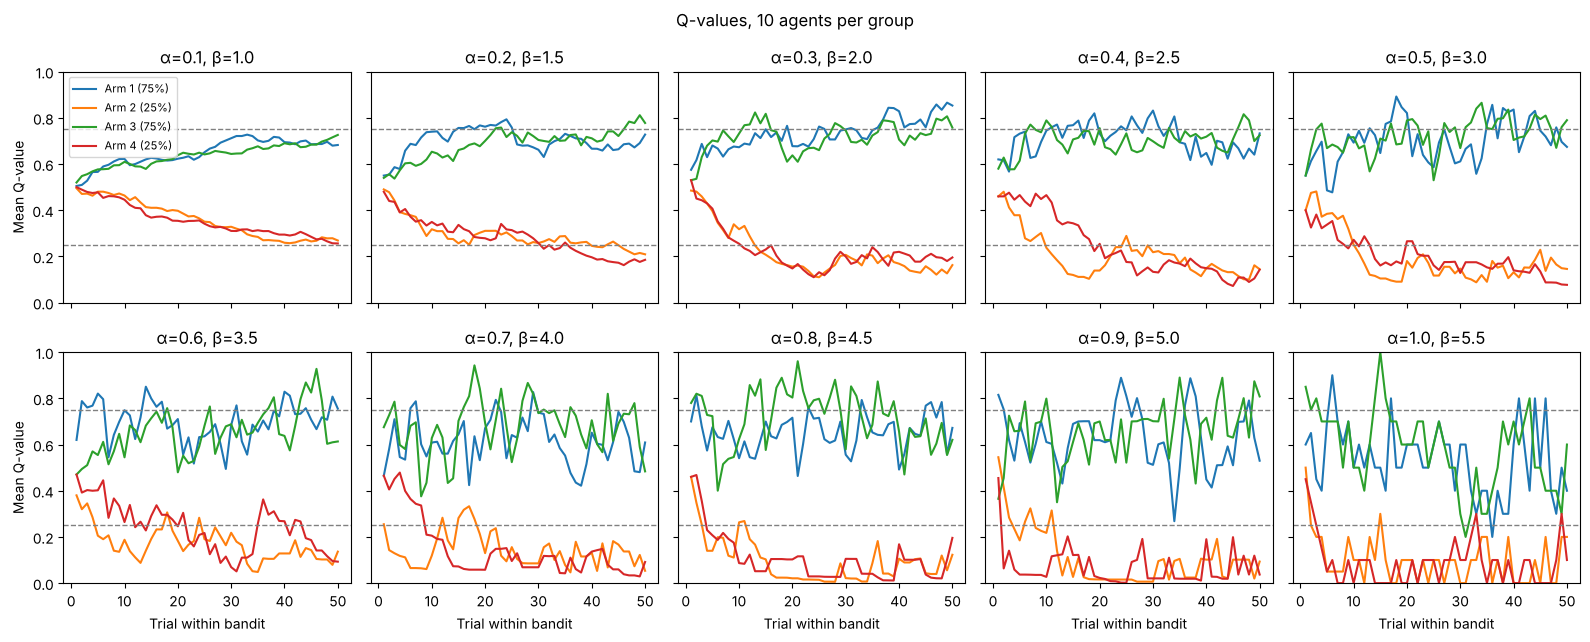

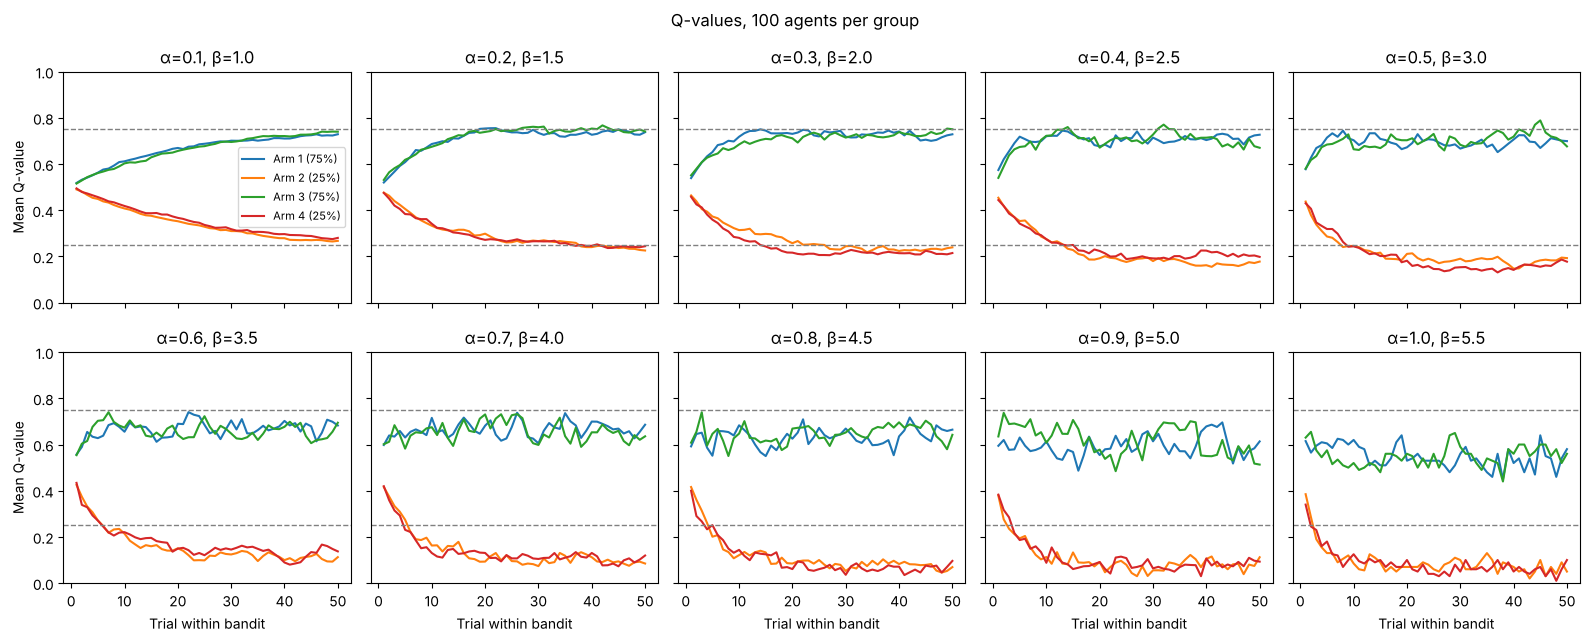

In [3]:
ARMS = [("Q_arm1", 1, "Arm 1 (75%)", "C0"), ("Q_arm2", 1, "Arm 2 (25%)", "C1"),
        ("Q_arm3", 2, "Arm 3 (75%)", "C2"), ("Q_arm4", 2, "Arm 4 (25%)", "C3")]

def plot_q_values(data, title, filename):
    fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharex=True, sharey=True)
    for group, ax in enumerate(axes.flat):
        rows = data[data["group"] == group]
        for column, pair, label, color in ARMS:
            # a bandit's Q-values are only read on that bandit's own trials
            curve = rows[rows["pair"] == pair].groupby("pair_trial")[column].mean()
            ax.plot(curve.index, curve.values, label=label, color=color)
        ax.axhline(0.75, linestyle="--", linewidth=1, color="grey")
        ax.axhline(0.25, linestyle="--", linewidth=1, color="grey")
        ax.set_title(f"α={alpha_parameters[group]}, β={beta_parameters[group]}")
        ax.set_ylim(0, 1)
    for ax in axes[1]:
        ax.set_xlabel("Trial within bandit")
    for ax in axes[:, 0]:
        ax.set_ylabel("Mean Q-value")
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

plot_q_values(sim_10, "Q-values, 10 agents per group", "outputs/q_values_10_per_group.png")
plot_q_values(sim_100, "Q-values, 100 agents per group", "outputs/q_values_100_per_group.png")

Going from 10 to 100 agents per group smooths the group means considerably. Individual agents with high α are still
jumpy trial to trial (with α = 1 the Q-value is simply the last outcome), but the group average converges.

Note that in the high-α/high-β groups the mean Q-values sit *below* the true reward probabilities (the 25% arm near 0.1, the 75% arm near 0.6). That is expected: these agents leave an arm right after it loses, so the arm they are not choosing keeps a Q-value frozen at a recent loss until they come back to it.

The choice curves below are closer to what we will see in behaviour.

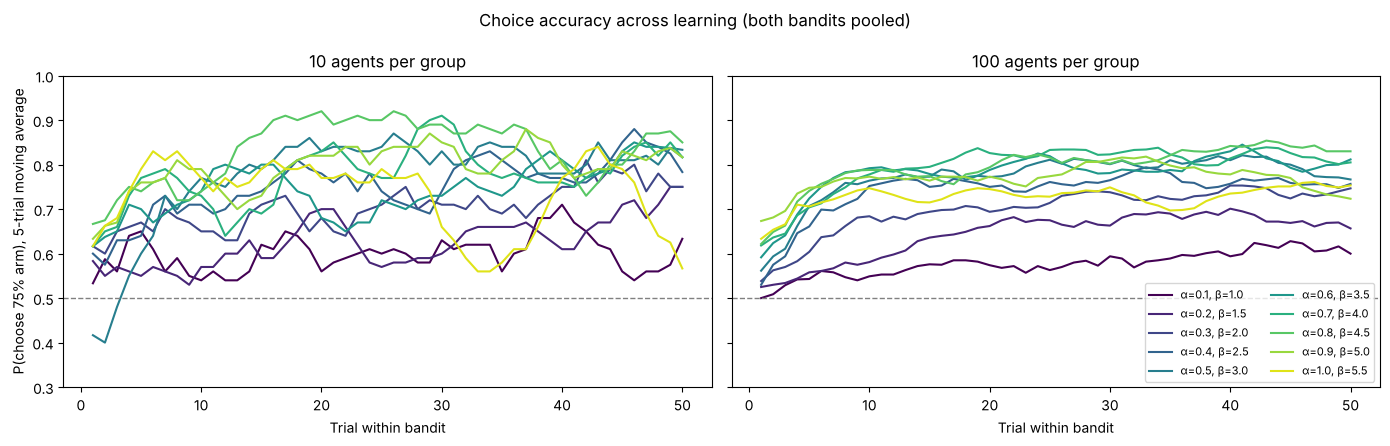

,alpha,beta,accuracy,win_rate,accuracy_last_10
group,,,,,
0,0.1,1.0,0.577,0.539,0.613
1,0.2,1.5,0.644,0.577,0.670
2,0.3,2.0,0.699,0.598,0.740
3,0.4,2.5,0.740,0.618,0.762
4,0.5,3.0,0.771,0.639,0.795
5,0.6,3.5,0.780,0.632,0.806
6,0.7,4.0,0.794,0.644,0.823
7,0.8,4.5,0.794,0.646,0.842
8,0.9,5.0,0.767,0.636,0.755


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.95, 10))
for ax, data, title in [(axes[0], sim_10, "10 agents per group"), (axes[1], sim_100, "100 agents per group")]:
    for group in range(10):
        curve = data[data["group"] == group].groupby("pair_trial")["chose_good"].mean()
        smooth = curve.rolling(5, center=True, min_periods=1).mean()
        ax.plot(smooth.index, smooth.values, color=colors[group],
                label=f"α={alpha_parameters[group]}, β={beta_parameters[group]}")
    ax.axhline(0.5, linestyle="--", linewidth=1, color="grey")
    ax.set_title(title)
    ax.set_xlabel("Trial within bandit")
    ax.set_ylim(0.3, 1)
axes[0].set_ylabel("P(choose 75% arm), 5-trial moving average")
axes[1].legend(fontsize=8, ncol=2)
fig.suptitle("Choice accuracy across learning (both bandits pooled)")
fig.tight_layout()
fig.savefig("outputs/choice_accuracy.png", dpi=150)
plt.show()

summary = sim_100.groupby("group").agg(alpha=("alpha", "first"), beta=("beta", "first"),
                                       accuracy=("chose_good", "mean"),
                                       win_rate=("outcome", "mean")).round(3)
late = sim_100[sim_100["pair_trial"] > 40].groupby("group")["chose_good"].mean().round(3)
summary["accuracy_last_10"] = late
summary

## 2. Parameter recovery on the paired groups

Each simulated agent is refit by maximum likelihood (coarse grid search for a starting point, then L-BFGS-B with
0 ≤ α ≤ 1 and 0 ≤ β ≤ 20). We then compare the fitted values against the values that generated the data.

When true α is at or near 1 the Q-values are just the last outcome (0 or 1), the likelihood is nearly flat in β, and the β estimate often runs off to large values. Read the β medians, not the means or SDs.

In [5]:
def recovery_stats(results):
    return {"alpha_pearson": pearsonr(results["alpha_true"], results["alpha_hat"])[0],
            "alpha_spearman": spearmanr(results["alpha_true"], results["alpha_hat"])[0],
            "beta_pearson": pearsonr(results["beta_true"], results["beta_hat"])[0],
            "beta_spearman": spearmanr(results["beta_true"], results["beta_hat"])[0],
            "beta_at_upper_bound": (results["beta_hat"] > rl.BETA_BOUNDS[1] - 0.01).mean(),
            "alpha_at_a_bound": ((results["alpha_hat"] < 0.01) | (results["alpha_hat"] > 0.99)).mean()}

rng = np.random.default_rng(SEED + 1)
paired = rl.run_recovery(np.repeat(alpha_parameters, 100), np.repeat(beta_parameters, 100), rng)
paired.to_csv("outputs/recovery_paired_groups.csv", index=False)
pd.Series(recovery_stats(paired)).round(3)

alpha_pearson          0.796
alpha_spearman         0.788
beta_pearson           0.361
beta_spearman          0.668
beta_at_upper_bound    0.100
alpha_at_a_bound       0.153
dtype: float64

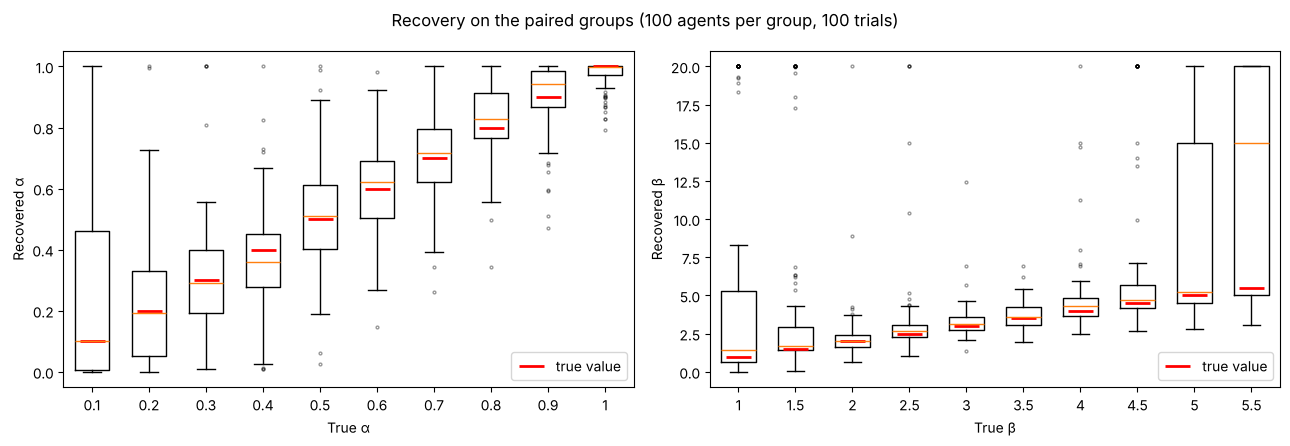

,,alpha_median,alpha_sd,beta_median,beta_sd
alpha_true,beta_true,,,,
0.1,1.0,0.10,0.36,1.44,7.87
0.2,1.5,0.19,0.22,1.71,6.29
0.3,2.0,0.29,0.19,2.01,2.03
0.4,2.5,0.36,0.18,2.65,3.34
0.5,3.0,0.51,0.18,3.14,1.20
0.6,3.5,0.62,0.16,3.57,0.88
0.7,4.0,0.72,0.15,4.31,2.43
0.8,4.5,0.83,0.12,4.71,5.06
0.9,5.0,0.94,0.11,5.25,6.37


In [6]:
def boxplot_by_true(ax, results, true_col, hat_col, label):
    values = sorted(results[true_col].unique())
    ax.boxplot([results.loc[results[true_col] == v, hat_col] for v in values],
               positions=range(len(values)), widths=0.6, showfliers=True,
               flierprops={"markersize": 2, "alpha": 0.4})
    ax.plot(range(len(values)), values, "r_", markersize=18, markeredgewidth=2, label="true value")
    ax.set_xticks(range(len(values)))
    ax.set_xticklabels([f"{v:g}" for v in values])
    ax.set_xlabel(f"True {label}")
    ax.set_ylabel(f"Recovered {label}")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
boxplot_by_true(axes[0], paired, "alpha_true", "alpha_hat", "α")
boxplot_by_true(axes[1], paired, "beta_true", "beta_hat", "β")
fig.suptitle("Recovery on the paired groups (100 agents per group, 100 trials)")
fig.tight_layout()
fig.savefig("outputs/recovery_paired_groups.png", dpi=150)
plt.show()

paired.groupby(["alpha_true", "beta_true"]).agg(
    alpha_median=("alpha_hat", "median"), alpha_sd=("alpha_hat", "std"),
    beta_median=("beta_hat", "median"), beta_sd=("beta_hat", "std")).round(2)

## 3. Parameter recovery on a crossed α × β grid

In the paired groups α and β rise together, so a correlation between true and recovered α could not be separated
from one driven by β. Here every α is crossed with every β (10 × 10 cells, 30 agents per cell).

In [7]:
AGENTS_PER_CELL = 30
grid_alpha, grid_beta = np.meshgrid(alpha_parameters, beta_parameters, indexing="ij")
crossed_alphas = np.repeat(grid_alpha.ravel(), AGENTS_PER_CELL)
crossed_betas = np.repeat(grid_beta.ravel(), AGENTS_PER_CELL)

rng = np.random.default_rng(SEED + 2)
crossed_100 = rl.run_recovery(crossed_alphas, crossed_betas, rng, trials_per_pair=50)
crossed_100.to_csv("outputs/recovery_crossed_100_trials.csv", index=False)
pd.Series(recovery_stats(crossed_100)).round(3)

alpha_pearson          0.831
alpha_spearman         0.829
beta_pearson           0.463
beta_spearman          0.786
beta_at_upper_bound    0.040
alpha_at_a_bound       0.120
dtype: float64

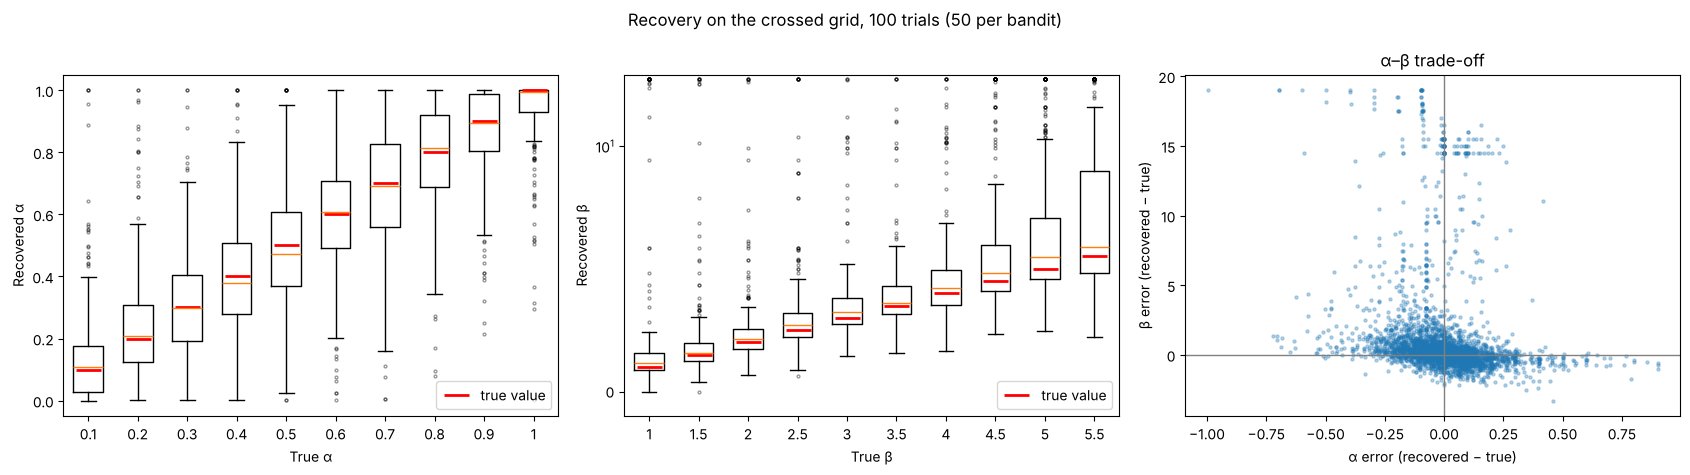

In [8]:
def plot_recovery(results, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    boxplot_by_true(axes[0], results, "alpha_true", "alpha_hat", "α")
    boxplot_by_true(axes[1], results, "beta_true", "beta_hat", "β")
    axes[1].set_yscale("symlog", linthresh=10)
    axes[2].scatter(results["alpha_hat"] - results["alpha_true"],
                    results["beta_hat"] - results["beta_true"], s=5, alpha=0.3)
    axes[2].axhline(0, color="grey", linewidth=1)
    axes[2].axvline(0, color="grey", linewidth=1)
    axes[2].set_xlabel("α error (recovered − true)")
    axes[2].set_ylabel("β error (recovered − true)")
    axes[2].set_title("α–β trade-off")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

plot_recovery(crossed_100, "Recovery on the crossed grid, 100 trials (50 per bandit)",
              "outputs/recovery_crossed_100_trials.png")

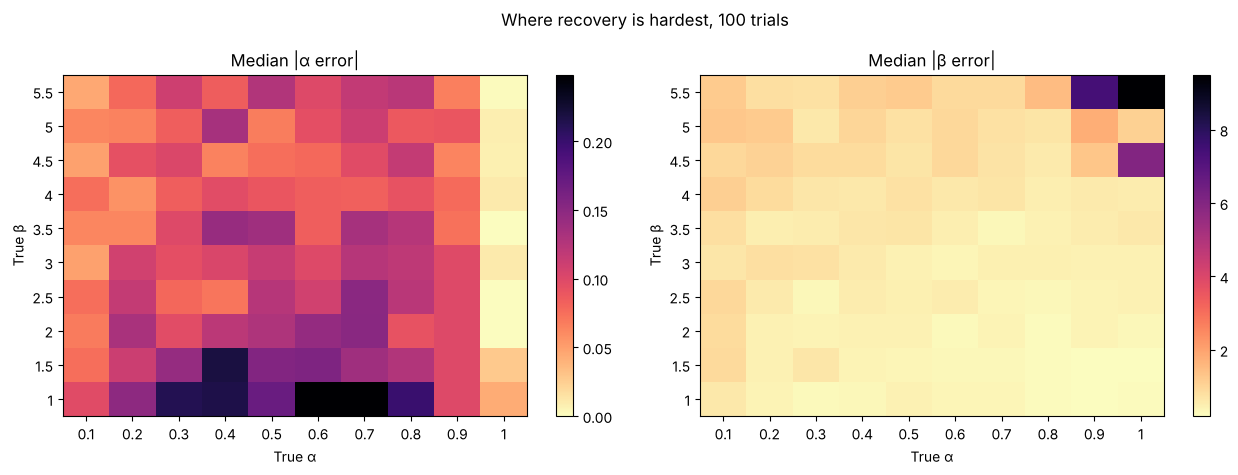

In [9]:
def plot_error_heatmaps(results, title, filename):
    cell = results.assign(alpha_abs_err=(results["alpha_hat"] - results["alpha_true"]).abs(),
                          beta_abs_err=(results["beta_hat"] - results["beta_true"]).abs())
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, column, label in [(axes[0], "alpha_abs_err", "Median |α error|"),
                              (axes[1], "beta_abs_err", "Median |β error|")]:
        table = cell.pivot_table(index="beta_true", columns="alpha_true", values=column, aggfunc="median")
        image = ax.imshow(table.values, origin="lower", aspect="auto", cmap="magma_r")
        ax.set_xticks(range(len(table.columns)))
        ax.set_xticklabels([f"{v:g}" for v in table.columns])
        ax.set_yticks(range(len(table.index)))
        ax.set_yticklabels([f"{v:g}" for v in table.index])
        ax.set_xlabel("True α")
        ax.set_ylabel("True β")
        ax.set_title(label)
        fig.colorbar(image, ax=ax)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

plot_error_heatmaps(crossed_100, "Where recovery is hardest, 100 trials", "outputs/recovery_error_heatmap_100_trials.png")

## 4. 100 trials versus 200 trials

Same grid and same number of agents, with 100 trials per bandit instead of 50, to show what the 100-trial limit costs.

In [10]:
rng = np.random.default_rng(SEED + 3)
crossed_200 = rl.run_recovery(crossed_alphas, crossed_betas, rng, trials_per_pair=100)
crossed_200.to_csv("outputs/recovery_crossed_200_trials.csv", index=False)

comparison = pd.DataFrame({"100 trials (50 per bandit)": recovery_stats(crossed_100),
                           "200 trials (100 per bandit)": recovery_stats(crossed_200)})
for name, results in [("100 trials (50 per bandit)", crossed_100), ("200 trials (100 per bandit)", crossed_200)]:
    comparison.loc["alpha_median_abs_error", name] = (results["alpha_hat"] - results["alpha_true"]).abs().median()
    comparison.loc["beta_median_abs_error", name] = (results["beta_hat"] - results["beta_true"]).abs().median()
comparison.to_csv("outputs/recovery_100_vs_200_trials.csv")
comparison.round(3)

,100 trials (50 per bandit),200 trials (100 per bandit)
alpha_pearson,0.831,0.913
alpha_spearman,0.829,0.913
beta_pearson,0.463,0.554
beta_spearman,0.786,0.895
beta_at_upper_bound,0.040,0.018
alpha_at_a_bound,0.120,0.089
alpha_median_abs_error,0.093,0.064
beta_median_abs_error,0.554,0.342


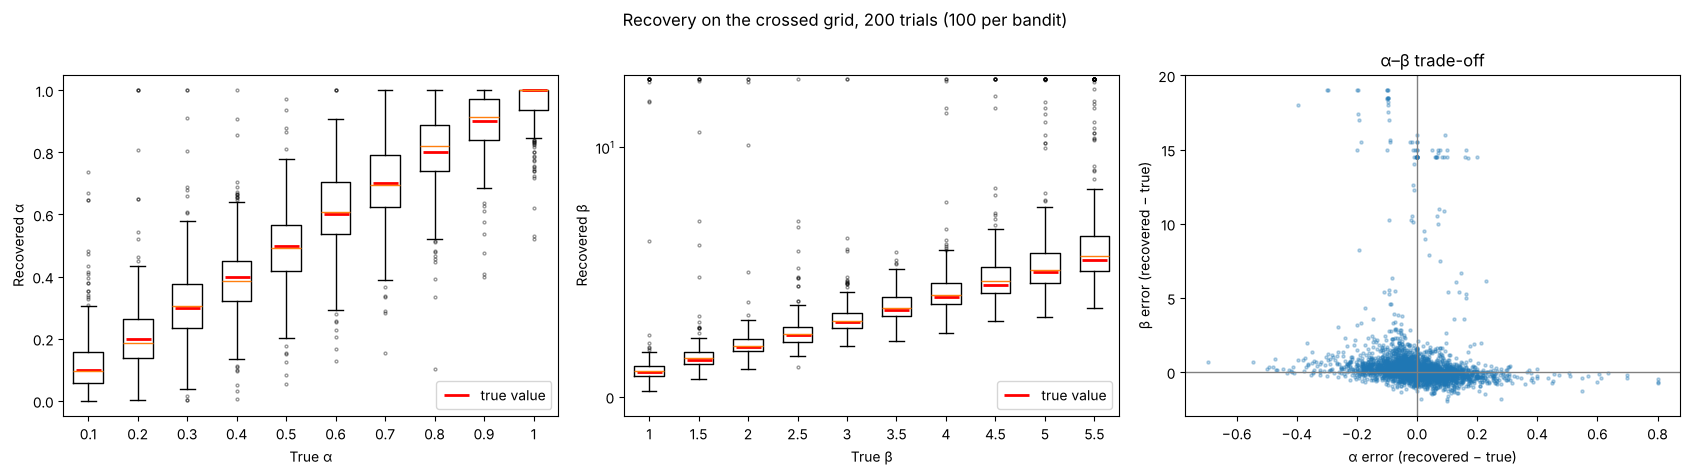

In [11]:
plot_recovery(crossed_200, "Recovery on the crossed grid, 200 trials (100 per bandit)",
              "outputs/recovery_crossed_200_trials.png")